In [2]:

import sys
import platform
import importlib.util

print("Python version:", sys.version)
print("Platform:", platform.platform())

for package in ["numpy", "pandas", "scipy", "matplotlib"]:
    print(
        package,
        "installed" if importlib.util.find_spec(package) else "not installed"
    )


Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
numpy installed
pandas installed
scipy installed
matplotlib installed


In [3]:

import shutil
import subprocess

print("\n=== NVIDIA GPU ===")

if shutil.which("nvidia-smi") is not None:
    try:
        result = subprocess.run(
            ["nvidia-smi"],
            capture_output=True,
            text=True,
            check=True
        )
        print(result.stdout)
    except subprocess.CalledProcessError as e:
        print("GPU check failed:", e.stderr)
else:
    print("No accessible NVIDIA GPU detected.")
    print("This project can run on the CPU.")



=== NVIDIA GPU ===
No accessible NVIDIA GPU detected.
This project can run on the CPU.


In [4]:

import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print("=== PIP DEPENDENCY CHECK ===")
print(result.stdout.strip() or "No broken requirements reported.")

if result.stderr.strip():
    print("Additional messages:")
    print(result.stderr)

print("Exit code:", result.returncode)


=== PIP DEPENDENCY CHECK ===
ipython 7.34.0 requires jedi, which is not installed.
Exit code: 1


=== IMPORT TEST ===
NumPy: 2.4.6
pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0
PASS: random-seed reproducibility
PASS: risk-score calculation
PASS: pandas data logging
   impact  uncertainty  reversibility  risk
0     0.8          0.9            0.0  0.72
1     0.5          0.4            0.5  0.10
2     1.0          0.7            1.0  0.00


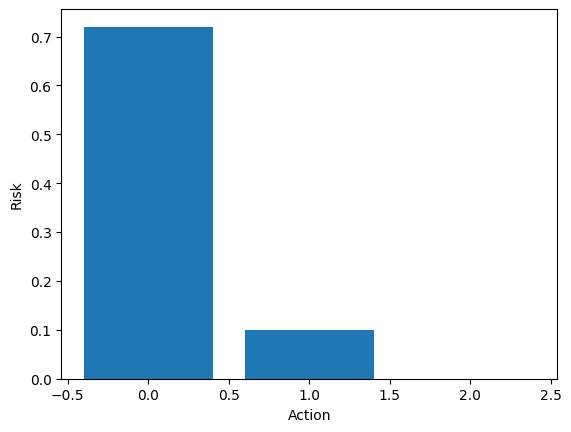

PASS: Matplotlib plotting

ENVIRONMENT TEST PASSED


In [5]:

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt

print("=== IMPORT TEST ===")
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)

# Reproducible random numbers
seed = 20261028
rng1 = np.random.default_rng(seed)
rng2 = np.random.default_rng(seed)

assert np.array_equal(rng1.random(5), rng2.random(5))
print("PASS: random-seed reproducibility")

# Proposed research risk score
impact = np.array([0.8, 0.5, 1.0])
uncertainty = np.array([0.9, 0.4, 0.7])
reversibility = np.array([0.0, 0.5, 1.0])

risk = impact * uncertainty * (1 - reversibility)

assert np.allclose(risk, [0.72, 0.10, 0.0])
print("PASS: risk-score calculation")

# Data logging
df = pd.DataFrame({
    "impact": impact,
    "uncertainty": uncertainty,
    "reversibility": reversibility,
    "risk": risk
})

assert len(df) == 3
print("PASS: pandas data logging")
print(df)

# Plotting
fig, ax = plt.subplots()
ax.bar(range(len(risk)), risk)
ax.set_xlabel("Action")
ax.set_ylabel("Risk")
plt.show()
plt.close(fig)

print("PASS: Matplotlib plotting")
print("\nENVIRONMENT TEST PASSED")


In [6]:

from pathlib import Path

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")

folders = [
    "configs",
    "src",
    "notebooks",
    "scripts",
    "data/generated",
    "data/splits",
    "results/raw",
    "results/summary",
    "results/figures",
    "tests",
    "paper",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("\nCreated project folders:")
for folder in folders:
    print("✓", folder)

print("\nPASS: Project structure created successfully.")


Project directory: /content/objective-uncertainty-rollback

Created project folders:
✓ configs
✓ src
✓ notebooks
✓ scripts
✓ data/generated
✓ data/splits
✓ results/raw
✓ results/summary
✓ results/figures
✓ tests
✓ paper

PASS: Project structure created successfully.


In [7]:

import json

config = {
    "project_name": "Objective-Uncertainty and Recovery Benchmark",
    "master_seed": 20261028,
    "primary_metric": "mean_residual_harm",
    "risk_formula": "impact * uncertainty * (1 - reversibility)",
    "risk_threshold": None,
    "policies": [
        "fixed_threshold_with_rollback",
        "fixed_threshold_without_rollback",
        "risk_aware_with_rollback"
    ],
    "test_results_viewed": False
}

config_path = PROJECT_DIR / "configs" / "experiment.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

print("Configuration saved to:", config_path)
print(json.dumps(config, indent=4))


Configuration saved to: /content/objective-uncertainty-rollback/configs/experiment.json
{
    "project_name": "Objective-Uncertainty and Recovery Benchmark",
    "master_seed": 20261028,
    "primary_metric": "mean_residual_harm",
    "risk_formula": "impact * uncertainty * (1 - reversibility)",
    "risk_threshold": null,
    "policies": [
        "fixed_threshold_with_rollback",
        "fixed_threshold_without_rollback",
        "risk_aware_with_rollback"
    ],
    "test_results_viewed": false
}


In [8]:

import numpy as np
import pandas as pd
import json

# Load the experiment configuration
config_path = PROJECT_DIR / "configs" / "experiment.json"

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

SEED = config["master_seed"]
rng = np.random.default_rng(SEED)

# Scenario families for the benchmark
scenario_families = [
    "file_operations",
    "database_updates",
    "external_messages",
    "financial_actions",
    "resource_management",
    "access_control"
]

rows = []
episodes_per_family = 100

for family in scenario_families:
    for i in range(episodes_per_family):
        impact = rng.uniform(0.1, 1.0)
        uncertainty = rng.uniform(0.0, 1.0)

        # Reversibility: 0 = irreversible, 1 = fully reversible
        reversibility = rng.choice(
            [0.0, 0.5, 1.0],
            p=[0.35, 0.30, 0.35]
        )

        risk = impact * uncertainty * (1 - reversibility)

        # Higher risk makes a harmful consequence more likely
        harm_probability = np.clip(
            0.05 + 0.75 * risk,
            0.0,
            1.0
        )
        harmful_outcome = int(rng.random() < harm_probability)

        rows.append({
            "episode_id": f"{family}_{i:03d}",
            "scenario_family": family,
            "impact": impact,
            "uncertainty": uncertainty,
            "reversibility": reversibility,
            "risk": risk,
            "harmful_outcome": harmful_outcome
        })

episodes = pd.DataFrame(rows)

# Validate the generated data
assert len(episodes) == 600
assert episodes["episode_id"].is_unique
assert episodes[["impact", "uncertainty", "reversibility"]].apply(
    lambda col: col.between(0, 1).all()
).all()

# Save generated scenarios
output_path = PROJECT_DIR / "data" / "generated" / "scenarios.csv"
episodes.to_csv(output_path, index=False)

print("PASS: Synthetic scenarios generated")
print("Total episodes:", len(episodes))
print("Scenario families:", episodes["scenario_family"].nunique())
print("Saved to:", output_path)
display(episodes.head(10))


PASS: Synthetic scenarios generated
Total episodes: 600
Scenario families: 6
Saved to: /content/objective-uncertainty-rollback/data/generated/scenarios.csv


,episode_id,scenario_family,impact,uncertainty,reversibility,risk,harmful_outcome
0,file_operations_000,file_operations,0.114429,0.169124,1.0,0.000000,1
1,file_operations_001,file_operations,0.604336,0.062140,1.0,0.000000,0
2,file_operations_002,file_operations,0.264381,0.198266,0.5,0.026209,0
3,file_operations_003,file_operations,0.611080,0.307122,1.0,0.000000,0
4,file_operations_004,file_operations,0.910752,0.992178,0.0,0.903628,0
5,file_operations_005,file_operations,0.782734,0.388490,0.0,0.304084,0
6,file_operations_006,file_operations,0.837542,0.064156,0.0,0.053733,0
7,file_operations_007,file_operations,0.164953,0.991039,0.0,0.163475,0
8,file_operations_008,file_operations,0.691226,0.917162,0.5,0.316983,0
9,file_operations_009,file_operations,0.479488,0.218807,1.0,0.000000,0


In [9]:

print("=== DATASET SUMMARY ===")
print("Rows:", len(episodes))
print("Columns:", len(episodes.columns))
print("\nEpisodes per family:")
display(episodes.groupby("scenario_family").size().rename("episodes"))

print("\nDescriptive statistics:")
display(
    episodes[
        ["impact", "uncertainty", "reversibility", "risk", "harmful_outcome"]
    ].describe().round(3)
)

print("\nMissing values:")
display(episodes.isna().sum().rename("missing_values"))

print("\nHarmful outcome rate:", round(
    episodes["harmful_outcome"].mean(), 3
))


=== DATASET SUMMARY ===
Rows: 600
Columns: 7

Episodes per family:


,episodes
scenario_family,
access_control,100
database_updates,100
external_messages,100
file_operations,100
financial_actions,100
resource_management,100



Descriptive statistics:


,impact,uncertainty,reversibility,risk,harmful_outcome
count,600.000,600.000,600.000,600.000,600.000
mean,0.546,0.496,0.508,0.128,0.165
std,0.255,0.300,0.413,0.174,0.371
min,0.101,0.001,0.000,0.000,0.000
25%,0.335,0.234,0.000,0.000,0.000
50%,0.539,0.477,0.500,0.053,0.000
75%,0.759,0.774,1.000,0.193,0.000
max,0.998,0.999,1.000,0.904,1.000



Missing values:


,missing_values
episode_id,0
scenario_family,0
impact,0
uncertainty,0
reversibility,0
risk,0
harmful_outcome,0



Harmful outcome rate: 0.165


In [10]:

import numpy as np
import pandas as pd

SPLIT_SEED = 20261028
split_rng = np.random.default_rng(SPLIT_SEED)

episodes = pd.read_csv(
    PROJECT_DIR / "data" / "generated" / "scenarios.csv"
)

# Assign 20 templates to each family, 5 episodes per template.
episodes["template_number"] = (
    episodes.groupby("scenario_family").cumcount() // 5
)

episodes["template_id"] = (
    episodes["scenario_family"]
    + "_template_"
    + episodes["template_number"].astype(str).str.zfill(2)
)

split_map = {}

for family in sorted(episodes["scenario_family"].unique()):
    templates = sorted(
        episodes.loc[
            episodes["scenario_family"] == family, "template_id"
        ].unique()
    )

    shuffled = split_rng.permutation(templates)

    for template in shuffled[:12]:
        split_map[template] = "development"

    for template in shuffled[12:16]:
        split_map[template] = "validation"

    for template in shuffled[16:20]:
        split_map[template] = "test"

episodes["split"] = episodes["template_id"].map(split_map)

# Confirm every template belongs to exactly one split.
assert episodes.groupby("template_id")["split"].nunique().max() == 1
assert episodes["split"].notna().all()

# Save split datasets
for split_name in ["development", "validation", "test"]:
    split_df = episodes[episodes["split"] == split_name].copy()

    split_path = (
        PROJECT_DIR / "data" / "splits" / f"{split_name}.csv"
    )
    split_df.to_csv(split_path, index=False)

    print(
        f"{split_name}: {len(split_df)} episodes, "
        f"{split_df['template_id'].nunique()} templates"
    )

print("\nEpisodes by split and family:")
display(pd.crosstab(episodes["scenario_family"], episodes["split"]))

print("\nPASS: Template-level split created.")


development: 360 episodes, 72 templates
validation: 120 episodes, 24 templates
test: 120 episodes, 24 templates

Episodes by split and family:


split,development,test,validation
scenario_family,,,
access_control,60,20,20
database_updates,60,20,20
external_messages,60,20,20
file_operations,60,20,20
financial_actions,60,20,20
resource_management,60,20,20



PASS: Template-level split created.


In [11]:

import numpy as np
import pandas as pd

# Load the three pre-generated splits
dev = pd.read_csv(PROJECT_DIR / "data/splits/development.csv")
val = pd.read_csv(PROJECT_DIR / "data/splits/validation.csv")
test = pd.read_csv(PROJECT_DIR / "data/splits/test.csv")

# Use development data to choose thresholds.
# These are predefined candidate thresholds, not learned model parameters.
thresholds = [0.10, 0.20, 0.30, 0.40]

def evaluate_policy(data, policy, threshold):
    d = data.copy()

    if policy == "fixed_threshold_with_rollback":
        d["intervene"] = d["risk"] >= threshold
        d["rollback"] = d["intervene"] & (d["reversibility"] > 0)

    elif policy == "fixed_threshold_without_rollback":
        d["intervene"] = d["risk"] >= threshold
        d["rollback"] = False

    elif policy == "risk_aware_with_rollback":
        # Provisional policy: lower threshold for higher impact/uncertainty.
        d["intervene"] = (
            d["risk"] >= threshold
        ) | (
            (d["impact"] >= 0.8) & (d["uncertainty"] >= 0.7)
        )
        d["rollback"] = d["intervene"] & (d["reversibility"] > 0)

    else:
        raise ValueError("Unknown policy")

    # Simplified outcome model:
    # reversible harmful outcomes are recoverable after rollback;
    # irreversible harmful outcomes remain harmful.
    d["residual_harm"] = (
        d["harmful_outcome"] *
        (~d["rollback"]).astype(int)
    )

    return {
        "mean_residual_harm": d["residual_harm"].mean(),
        "task_success_rate": 1 - d["residual_harm"].mean(),
        "intervention_rate": d["intervene"].mean(),
        "false_intervention_rate": (
            d["intervene"] & (d["harmful_outcome"] == 0)
        ).mean(),
        "rollback_rate": d["rollback"].mean()
    }

# Choose the fixed threshold on development data only.
dev_results = []

for threshold in thresholds:
    result = evaluate_policy(
        dev, "fixed_threshold_with_rollback", threshold
    )
    dev_results.append({
        "threshold": threshold,
        **result
    })

dev_results = pd.DataFrame(dev_results)
display(dev_results)

best_threshold = dev_results.sort_values(
    "mean_residual_harm"
).iloc[0]["threshold"]

print("Selected development threshold:", best_threshold)


,threshold,mean_residual_harm,task_success_rate,intervention_rate,false_intervention_rate,rollback_rate
0,0.1,0.122222,0.877778,0.411111,0.291667,0.175000
1,0.2,0.150000,0.850000,0.225000,0.138889,0.072222
2,0.3,0.158333,0.841667,0.161111,0.091667,0.030556
3,0.4,0.163889,0.836111,0.094444,0.050000,0.005556


Selected development threshold: 0.1


In [12]:

import numpy as np
import pandas as pd

# Explicit simulation assumption, to be documented in the paper:
# Rollback recovers at most 80% of harm for a fully reversible action.
ROLLBACK_RECOVERY = 0.80

def evaluate_policy(data, policy, threshold):
    d = data.copy()

    # Monitoring decision
    if policy in [
        "fixed_threshold_with_rollback",
        "fixed_threshold_without_rollback"
    ]:
        d["intervene"] = d["risk"] >= threshold

    elif policy == "risk_aware_with_rollback":
        d["intervene"] = (
            (d["risk"] >= threshold)
            | (
                (d["impact"] >= 0.8)
                & (d["uncertainty"] >= 0.7)
            )
        )
    else:
        raise ValueError(f"Unknown policy: {policy}")

    # Rollback is only available in policies that include it.
    if policy in [
        "fixed_threshold_with_rollback",
        "risk_aware_with_rollback"
    ]:
        d["rollback"] = (
            d["intervene"] & (d["reversibility"] > 0)
        )
    else:
        d["rollback"] = False

    # Residual harm is impact-weighted.
    # Irreversible harm cannot be recovered by this rollback model.
    recovery_fraction = np.where(
        d["rollback"],
        ROLLBACK_RECOVERY * d["reversibility"],
        0.0
    )

    d["residual_harm"] = (
        d["harmful_outcome"]
        * d["impact"]
        * (1.0 - recovery_fraction)
    )

    # False-positive rate: fraction of benign episodes flagged.
    benign = d["harmful_outcome"] == 0
    false_positives = (d["intervene"] & benign).sum()
    benign_count = benign.sum()

    false_positive_rate = (
        false_positives / benign_count
        if benign_count else np.nan
    )

    return {
        "mean_residual_harm": d["residual_harm"].mean(),
        "intervention_rate": d["intervene"].mean(),
        "false_positive_rate": false_positive_rate,
        "rollback_rate": d["rollback"].mean()
    }


# Select threshold using development data only.
dev = pd.read_csv(
    PROJECT_DIR / "data/splits/development.csv"
)

thresholds = [0.10, 0.20, 0.30, 0.40]
results = []

for threshold in thresholds:
    metrics = evaluate_policy(
        dev,
        "fixed_threshold_with_rollback",
        threshold
    )
    results.append({
        "threshold": threshold,
        **metrics
    })

threshold_results = pd.DataFrame(results)
display(threshold_results.round(4))

best_threshold = threshold_results.loc[
    threshold_results["mean_residual_harm"].idxmin(),
    "threshold"
]

print("Selected threshold on development data:", best_threshold)
print("Rollback recovery assumption:", ROLLBACK_RECOVERY)
print("PASS: Corrected evaluation model executed.")


,threshold,mean_residual_harm,intervention_rate,false_positive_rate,rollback_rate
0,0.1,0.0849,0.4111,0.3500,0.1750
1,0.2,0.0910,0.2250,0.1667,0.0722
2,0.3,0.0935,0.1611,0.1100,0.0306
3,0.4,0.0954,0.0944,0.0600,0.0056


Selected threshold on development data: 0.1
Rollback recovery assumption: 0.8
PASS: Corrected evaluation model executed.


In [13]:

import pandas as pd
import json

val = pd.read_csv(
    PROJECT_DIR / "data/splits/validation.csv"
)

policies = [
    "fixed_threshold_with_rollback",
    "fixed_threshold_without_rollback",
    "risk_aware_with_rollback"
]

validation_results = []

for policy in policies:
    metrics = evaluate_policy(
        val,
        policy,
        float(best_threshold)
    )

    validation_results.append({
        "policy": policy,
        "threshold": float(best_threshold),
        **metrics
    })

validation_df = pd.DataFrame(validation_results)

print("=== VALIDATION RESULTS ===")
display(validation_df.round(4))

results_path = (
    PROJECT_DIR / "results" / "summary" / "validation_results.csv"
)
validation_df.to_csv(results_path, index=False)

print("Saved validation results to:", results_path)


=== VALIDATION RESULTS ===


,policy,threshold,mean_residual_harm,intervention_rate,false_positive_rate,rollback_rate
0,fixed_threshold_with_rollback,0.1,0.0996,0.450,0.3438,0.1667
1,fixed_threshold_without_rollback,0.1,0.1194,0.450,0.3438,0.0000
2,risk_aware_with_rollback,0.1,0.0996,0.475,0.3750,0.1917


Saved validation results to: /content/objective-uncertainty-rollback/results/summary/validation_results.csv


In [14]:

import json
from pathlib import Path

summary_dir = PROJECT_DIR / "results" / "summary"
summary_dir.mkdir(parents=True, exist_ok=True)

# Preserve the validation results already calculated.
validation_df.to_csv(
    summary_dir / "validation_results.csv",
    index=False
)

decision_log = {
    "selected_threshold": float(best_threshold),
    "selection_data": "development",
    "validation_evaluated": True,
    "risk_aware_advantage_demonstrated": False,
    "next_step": (
        "Improve and document the simulator before final test evaluation"
    ),
    "interpretation": (
        "Preliminary synthetic results only; no real-world claim."
    )
}

with open(
    summary_dir / "validation_decision.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(decision_log, f, indent=4)

print("PASS: Validation results preserved.")
print("Selected threshold:", best_threshold)
print("Risk-aware advantage demonstrated: No")
print("Decision log:", summary_dir / "validation_decision.json")


PASS: Validation results preserved.
Selected threshold: 0.1
Risk-aware advantage demonstrated: No
Decision log: /content/objective-uncertainty-rollback/results/summary/validation_decision.json


In [15]:

from pathlib import Path
import pandas as pd
import json

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")

print("=== PROJECT FILE CHECK ===")

files_to_check = [
    "configs/experiment.json",
    "data/generated/scenarios.csv",
    "data/splits/development.csv",
    "data/splits/validation.csv",
    "data/splits/test.csv",
    "results/summary/validation_results.csv",
    "results/summary/validation_decision.json",
]

for filename in files_to_check:
    path = PROJECT_DIR / filename
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {filename}")

print("\n=== DATASET VALIDATION ===")

dataset_path = PROJECT_DIR / "data/generated/scenarios.csv"

if dataset_path.exists():
    df = pd.read_csv(dataset_path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:", int(df.isna().sum().sum()))
    print("Duplicate episode IDs:", int(df["episode_id"].duplicated().sum()))
    print("\nFirst five rows:")
    display(df.head())

    required = {
        "episode_id", "scenario_family", "impact",
        "uncertainty", "reversibility", "risk",
        "harmful_outcome"
    }

    assert required.issubset(df.columns), "Required columns are missing."
    assert len(df) == 600, "Expected 600 episodes."
    assert df["episode_id"].is_unique, "Episode IDs are not unique."
    assert df.isna().sum().sum() == 0, "Missing values detected."

    print("\nPASS: Basic dataset validation")
else:
    print("Dataset not found. Do not regenerate it yet.")


=== PROJECT FILE CHECK ===
FOUND: configs/experiment.json
FOUND: data/generated/scenarios.csv
FOUND: data/splits/development.csv
FOUND: data/splits/validation.csv
FOUND: data/splits/test.csv
FOUND: results/summary/validation_results.csv
FOUND: results/summary/validation_decision.json

=== DATASET VALIDATION ===
Shape: (600, 7)
Columns: ['episode_id', 'scenario_family', 'impact', 'uncertainty', 'reversibility', 'risk', 'harmful_outcome']
Missing values: 0
Duplicate episode IDs: 0

First five rows:


,episode_id,scenario_family,impact,uncertainty,reversibility,risk,harmful_outcome
0,file_operations_000,file_operations,0.114429,0.169124,1.0,0.000000,1
1,file_operations_001,file_operations,0.604336,0.062140,1.0,0.000000,0
2,file_operations_002,file_operations,0.264381,0.198266,0.5,0.026209,0
3,file_operations_003,file_operations,0.611080,0.307122,1.0,0.000000,0
4,file_operations_004,file_operations,0.910752,0.992178,0.0,0.903628,0



PASS: Basic dataset validation


In [16]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
SPLIT_DIR = PROJECT_DIR / "data" / "splits"

split_files = {
    "development": SPLIT_DIR / "development.csv",
    "validation": SPLIT_DIR / "validation.csv",
    "test": SPLIT_DIR / "test.csv",
}

print("=== SPLIT VALIDATION ===")

# 1. Load the three existing splits
splits = {}

for name, path in split_files.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing split file: {path}")

    splits[name] = pd.read_csv(path)
    print(f"{name}: {len(splits[name])} rows")

# 2. Check required columns
required_columns = {"episode_id", "scenario_family"}

for name, df in splits.items():
    missing = required_columns - set(df.columns)
    assert not missing, f"{name} is missing columns: {missing}"

# 3. Check for episode ID overlap between splits
print("\n=== EPISODE OVERLAP ===")

episode_sets = {
    name: set(df["episode_id"])
    for name, df in splits.items()
}

for a, b in [
    ("development", "validation"),
    ("development", "test"),
    ("validation", "test"),
]:
    overlap = episode_sets[a] & episode_sets[b]
    print(f"{a} vs {b}: {len(overlap)} shared episode IDs")

# 4. Check scenario-family balance
print("\n=== SCENARIO FAMILY COUNTS ===")

for name, df in splits.items():
    print(f"\n{name}:")
    print(df["scenario_family"].value_counts().sort_index().to_string())

# 5. Check template leakage, if template_id exists
print("\n=== TEMPLATE LEAKAGE CHECK ===")

if all("template_id" in df.columns for df in splits.values()):
    template_sets = {
        name: set(df["template_id"])
        for name, df in splits.items()
    }

    for a, b in [
        ("development", "validation"),
        ("development", "test"),
        ("validation", "test"),
    ]:
        overlap = template_sets[a] & template_sets[b]
        print(f"{a} vs {b}: {len(overlap)} shared template IDs")
else:
    print("template_id is missing from at least one split.")
    print("Template leakage cannot be checked using these files.")

# 6. Check total row count and episode uniqueness
all_ids = pd.concat(
    [df["episode_id"] for df in splits.values()],
    ignore_index=True
)

print("\n=== FINAL CHECKS ===")
print("Total split rows:", len(all_ids))
print("Unique episode IDs across splits:", all_ids.nunique())
print("Rows with duplicate IDs across splits:", all_ids.duplicated().sum())

assert len(all_ids) == 600, "Expected 600 rows across all splits."
assert all_ids.nunique() == 600, "Episode IDs overlap across splits."

print("\nPASS: Split sizes and episode separation checks")


=== SPLIT VALIDATION ===
development: 360 rows
validation: 120 rows
test: 120 rows

=== EPISODE OVERLAP ===
development vs validation: 0 shared episode IDs
development vs test: 0 shared episode IDs
validation vs test: 0 shared episode IDs

=== SCENARIO FAMILY COUNTS ===

development:
scenario_family
access_control         60
database_updates       60
external_messages      60
file_operations        60
financial_actions      60
resource_management    60

validation:
scenario_family
access_control         20
database_updates       20
external_messages      20
file_operations        20
financial_actions      20
resource_management    20

test:
scenario_family
access_control         20
database_updates       20
external_messages      20
file_operations        20
financial_actions      20
resource_management    20

=== TEMPLATE LEAKAGE CHECK ===
development vs validation: 0 shared template IDs
development vs test: 0 shared template IDs
validation vs test: 0 shared template IDs

=== FINAL CH

In [17]:

from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")

print("=== SOURCE FILES ===")
for folder in ["src", "scripts", "tests"]:
    directory = PROJECT_DIR / folder
    print(f"\n{folder}/")

    if directory.exists():
        files = sorted(directory.rglob("*.py"))
        if files:
            for file in files:
                print(" -", file.relative_to(PROJECT_DIR))
        else:
            print(" (no Python files found)")
    else:
        print(" (folder missing)")

print("\n=== EXPERIMENT CONFIGURATION ===")
config_path = PROJECT_DIR / "configs" / "experiment.json"

if config_path.exists():
    config = json.loads(config_path.read_text())
    print(json.dumps(config, indent=2))
else:
    print("experiment.json not found")

print("\n=== SPLIT SCHEMAS ===")
for name in ["development", "validation", "test"]:
    path = PROJECT_DIR / "data" / "splits" / f"{name}.csv"

    if path.exists():
        df = pd.read_csv(path)
        print(f"\n{name}:")
        print("Columns:", df.columns.tolist())
        if "template_id" in df.columns:
            print("Unique template IDs:", df["template_id"].nunique())

print("\n=== EXISTING VALIDATION RESULTS ===")
results_path = (
    PROJECT_DIR / "results" / "summary" / "validation_results.csv"
)

if results_path.exists():
    print(pd.read_csv(results_path).to_string(index=False))
else:
    print("No saved validation results found.")

print("\nInspection complete. No files were changed.")


=== SOURCE FILES ===

src/
 (no Python files found)

scripts/
 (no Python files found)

tests/
 (no Python files found)

=== EXPERIMENT CONFIGURATION ===
{
  "project_name": "Objective-Uncertainty and Recovery Benchmark",
  "master_seed": 20261028,
  "primary_metric": "mean_residual_harm",
  "risk_formula": "impact * uncertainty * (1 - reversibility)",
  "risk_threshold": null,
  "policies": [
    "fixed_threshold_with_rollback",
    "fixed_threshold_without_rollback",
    "risk_aware_with_rollback"
  ],
  "test_results_viewed": false
}

=== SPLIT SCHEMAS ===

development:
Columns: ['episode_id', 'scenario_family', 'impact', 'uncertainty', 'reversibility', 'risk', 'harmful_outcome', 'template_number', 'template_id', 'split']
Unique template IDs: 72

validation:
Columns: ['episode_id', 'scenario_family', 'impact', 'uncertainty', 'reversibility', 'risk', 'harmful_outcome', 'template_number', 'template_id', 'split']
Unique template IDs: 24

test:
Columns: ['episode_id', 'scenario_family',

In [18]:

from pathlib import Path
import json

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"

print("=== NOTEBOOK FILES ===")

notebooks = sorted(NOTEBOOK_DIR.glob("*.ipynb"))

if not notebooks:
    print("No Jupyter notebooks found in the notebooks folder.")
else:
    for path in notebooks:
        print(f"\nNotebook: {path.name}")

        with path.open("r", encoding="utf-8") as f:
            notebook = json.load(f)

        for i, cell in enumerate(notebook.get("cells", [])):
            source = "".join(cell.get("source", []))
            if not source.strip():
                continue

            # Show headings and code that may define the simulation.
            is_heading = (
                cell.get("cell_type") == "markdown"
                and any(line.lstrip().startswith("#") for line in source.splitlines())
            )

            keywords = [
                "rollback", "residual_harm", "threshold",
                "policy", "harmful_outcome", "recovery",
                "intervention", "random.seed", "default_rng"
            ]

            is_relevant_code = (
                cell.get("cell_type") == "code"
                and any(word in source.lower() for word in keywords)
            )

            if is_heading or is_relevant_code:
                print(f"\n--- Cell {i} ({cell.get('cell_type')}) ---")
                print(source[:2500])
                if len(source) > 2500:
                    print("... [cell truncated]")

print("\nNotebook inspection complete. No files were changed.")


=== NOTEBOOK FILES ===
No Jupyter notebooks found in the notebooks folder.

Notebook inspection complete. No files were changed.


In [19]:

from pathlib import Path
import sys
import math

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

simulator_code = '''"""Simple risk and residual-harm simulator.

This is a new, simplified implementation for controlled experiments.
It is not a reproduction of a published baseline.
"""

import math


def _validate_unit_interval(name, value):
    """Require a finite numeric value in [0, 1]."""
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        raise TypeError(f"{name} must be a numeric value.")
    if not math.isfinite(value) or not 0.0 <= value <= 1.0:
        raise ValueError(f"{name} must be between 0 and 1.")


def calculate_risk(impact, uncertainty, reversibility):
    """Calculate risk = impact * uncertainty * (1 - reversibility)."""
    _validate_unit_interval("impact", impact)
    _validate_unit_interval("uncertainty", uncertainty)
    _validate_unit_interval("reversibility", reversibility)

    return impact * uncertainty * (1.0 - reversibility)


def simulate_outcome(
    impact,
    uncertainty,
    reversibility,
    harmful_outcome,
    rollback_attempted=False,
    recovery_fraction=0.80,
):
    """Return risk and harm estimates for one simulated action.

    Initial harm = impact * harmful_outcome.
    Rollback recovery = initial harm * recovery_fraction * reversibility,
    but only when rollback_attempted is True.
    """
    _validate_unit_interval("impact", impact)
    _validate_unit_interval("uncertainty", uncertainty)
    _validate_unit_interval("reversibility", reversibility)
    _validate_unit_interval("recovery_fraction", recovery_fraction)

    if isinstance(harmful_outcome, bool):
        harmful = int(harmful_outcome)
    elif isinstance(harmful_outcome, int) and harmful_outcome in (0, 1):
        harmful = harmful_outcome
    else:
        raise ValueError("harmful_outcome must be 0 or 1.")

    if not isinstance(rollback_attempted, bool):
        raise TypeError("rollback_attempted must be True or False.")

    risk = calculate_risk(impact, uncertainty, reversibility)
    initial_harm = impact * harmful

    recovery_rate = (
        recovery_fraction * reversibility
        if rollback_attempted
        else 0.0
    )

    harm_recovered = initial_harm * recovery_rate
    residual_harm = initial_harm - harm_recovered

    return {
        "risk": risk,
        "initial_harm": initial_harm,
        "harm_recovered": harm_recovered,
        "residual_harm": residual_harm,
        "rollback_attempted": rollback_attempted,
    }
'''

module_path = SRC_DIR / "simulator.py"
module_path.write_text(simulator_code, encoding="utf-8")

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import simulator

print("=== SIMULATOR SANITY TESTS ===")

# Test 1: No harmful outcome means no harm.
result = simulator.simulate_outcome(
    impact=0.8,
    uncertainty=0.7,
    reversibility=1.0,
    harmful_outcome=0,
    rollback_attempted=True,
)
assert result["initial_harm"] == 0.0
assert result["residual_harm"] == 0.0
print("PASS: No harmful outcome produces zero harm")

# Test 2: Fully reversible action recovers 80% of initial harm.
result = simulator.simulate_outcome(
    impact=0.5,
    uncertainty=0.8,
    reversibility=1.0,
    harmful_outcome=1,
    rollback_attempted=True,
)
assert math.isclose(result["initial_harm"], 0.5)
assert math.isclose(result["harm_recovered"], 0.4)
assert math.isclose(result["residual_harm"], 0.1)
print("PASS: Reversible rollback recovers the specified 80%")

# Test 3: Irreversible action cannot recover harm through rollback.
result = simulator.simulate_outcome(
    impact=0.9,
    uncertainty=0.6,
    reversibility=0.0,
    harmful_outcome=1,
    rollback_attempted=True,
)
assert math.isclose(result["residual_harm"], 0.9)
assert math.isclose(result["harm_recovered"], 0.0)
print("PASS: Irreversible action has no rollback recovery")

# Test 4: Risk formula.
risk = simulator.calculate_risk(0.8, 0.5, 0.25)
assert math.isclose(risk, 0.3)
print("PASS: Risk formula returns the expected value")

# Test 5: Invalid input is rejected.
try:
    simulator.calculate_risk(1.2, 0.5, 0.5)
except ValueError:
    print("PASS: Out-of-range input is rejected")
else:
    raise AssertionError("Out-of-range input was not rejected")

print("\nSaved module:", module_path)
print("All simulator sanity tests passed.")


=== SIMULATOR SANITY TESTS ===
PASS: No harmful outcome produces zero harm
PASS: Reversible rollback recovers the specified 80%
PASS: Irreversible action has no rollback recovery
PASS: Risk formula returns the expected value
PASS: Out-of-range input is rejected

Saved module: /content/objective-uncertainty-rollback/src/simulator.py
All simulator sanity tests passed.


In [20]:

from pathlib import Path
import sys
import math
import pandas as pd

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

policies_code = '''"""Policy decisions for the objective-uncertainty benchmark.

Design choice:
- Fixed-threshold policies monitor uncertainty alone.
- The risk-aware policy monitors impact * uncertainty * (1 - reversibility).

This is a simplified operationalization, not a reproduction of a
specific published implementation.
"""

from simulator import calculate_risk


VALID_POLICIES = {
    "fixed_threshold_with_rollback",
    "fixed_threshold_without_rollback",
    "risk_aware_with_rollback",
}


def decide_action(impact, uncertainty, reversibility, policy, threshold):
    """Return intervention and rollback decisions for one episode."""
    if policy not in VALID_POLICIES:
        raise ValueError(f"Unknown policy: {policy}")

    if isinstance(threshold, bool) or not isinstance(threshold, (int, float)):
        raise TypeError("threshold must be numeric")

    if not 0.0 <= threshold <= 1.0:
        raise ValueError("threshold must be between 0 and 1")

    risk = calculate_risk(impact, uncertainty, reversibility)

    if policy.startswith("fixed_threshold"):
        score = uncertainty
    else:
        score = risk

    # An episode is flagged when its score meets or exceeds the threshold.
    intervene = score >= threshold

    rollback = (
        intervene
        and policy in {
            "fixed_threshold_with_rollback",
            "risk_aware_with_rollback",
        }
    )

    return {
        "score": score,
        "risk": risk,
        "intervene": intervene,
        "rollback_attempted": rollback,
    }
'''

module_path = SRC_DIR / "policies.py"
module_path.write_text(policies_code, encoding="utf-8")

import policies

print("=== POLICY SANITY TESTS ===")

# Example A: high uncertainty, but low composite risk.
a = policies.decide_action(
    impact=0.2,
    uncertainty=0.8,
    reversibility=1.0,
    policy="fixed_threshold_with_rollback",
    threshold=0.5,
)
assert a["intervene"] is True
assert a["rollback_attempted"] is True
print("PASS: Fixed-threshold policy flags high uncertainty")

# The same episode has zero composite risk because it is fully reversible.
b = policies.decide_action(
    impact=0.2,
    uncertainty=0.8,
    reversibility=1.0,
    policy="risk_aware_with_rollback",
    threshold=0.5,
)
assert math.isclose(b["risk"], 0.0)
assert b["intervene"] is False
assert b["rollback_attempted"] is False
print("PASS: Risk-aware policy uses the composite risk score")

# Without-rollback policy can intervene but must not attempt rollback.
c = policies.decide_action(
    impact=0.9,
    uncertainty=0.8,
    reversibility=0.0,
    policy="fixed_threshold_without_rollback",
    threshold=0.5,
)
assert c["intervene"] is True
assert c["rollback_attempted"] is False
print("PASS: No-rollback policy never attempts rollback")

# Invalid policy should fail clearly.
try:
    policies.decide_action(
        0.5, 0.5, 0.5, "unknown_policy", 0.5
    )
except ValueError:
    print("PASS: Unknown policy is rejected")
else:
    raise AssertionError("Unknown policy was not rejected")

print("\nSaved module:", module_path)
print("All policy sanity tests passed.")


=== POLICY SANITY TESTS ===
PASS: Fixed-threshold policy flags high uncertainty
PASS: Risk-aware policy uses the composite risk score
PASS: No-rollback policy never attempts rollback
PASS: Unknown policy is rejected

Saved module: /content/objective-uncertainty-rollback/src/policies.py
All policy sanity tests passed.


In [21]:

from pathlib import Path
import sys
import math
import pandas as pd

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

evaluation_code = '''"""Evaluation metrics for simulated intervention policies."""

import pandas as pd

from policies import decide_action
from simulator import simulate_outcome


REQUIRED_COLUMNS = {
    "episode_id",
    "impact",
    "uncertainty",
    "reversibility",
    "harmful_outcome",
}


def evaluate_policy(
    df,
    policy,
    threshold,
    recovery_fraction=0.80,
):
    """Evaluate one policy on a dataframe.

    Returns:
        summary: one-row dictionary of aggregate metrics
        predictions: per-episode decisions and harm estimates

    False-positive rate is:
        interventions on non-harmful episodes / all non-harmful episodes.
    """
    missing = REQUIRED_COLUMNS - set(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    if df.empty:
        raise ValueError("Cannot evaluate an empty dataframe.")

    if df["episode_id"].duplicated().any():
        raise ValueError("episode_id values must be unique.")

    records = []

    for row in df.to_dict(orient="records"):
        impact = float(row["impact"])
        uncertainty = float(row["uncertainty"])
        reversibility = float(row["reversibility"])
        harmful_outcome = int(row["harmful_outcome"])

        decision = decide_action(
            impact=impact,
            uncertainty=uncertainty,
            reversibility=reversibility,
            policy=policy,
            threshold=float(threshold),
        )

        outcome = simulate_outcome(
            impact=impact,
            uncertainty=uncertainty,
            reversibility=reversibility,
            harmful_outcome=harmful_outcome,
            rollback_attempted=decision["rollback_attempted"],
            recovery_fraction=float(recovery_fraction),
        )

        records.append({
            "episode_id": row["episode_id"],
            "policy": policy,
            "threshold": float(threshold),
            "impact": impact,
            "uncertainty": uncertainty,
            "reversibility": reversibility,
            "harmful_outcome": harmful_outcome,
            "risk": outcome["risk"],
            "intervene": decision["intervene"],
            "rollback_attempted": outcome["rollback_attempted"],
            "initial_harm": outcome["initial_harm"],
            "harm_recovered": outcome["harm_recovered"],
            "residual_harm": outcome["residual_harm"],
        })

    predictions = pd.DataFrame(records)

    non_harmful = predictions["harmful_outcome"] == 0
    false_positive_rate = (
        predictions.loc[non_harmful, "intervene"].mean()
        if non_harmful.any()
        else float("nan")
    )

    summary = {
        "policy": policy,
        "threshold": float(threshold),
        "n_episodes": int(len(predictions)),
        "mean_residual_harm": float(predictions["residual_harm"].mean()),
        "intervention_rate": float(predictions["intervene"].mean()),
        "false_positive_rate": float(false_positive_rate),
        "rollback_rate": float(predictions["rollback_attempted"].mean()),
        "mean_initial_harm": float(predictions["initial_harm"].mean()),
        "mean_harm_recovered": float(predictions["harm_recovered"].mean()),
    }

    return summary, predictions
'''

module_path = SRC_DIR / "evaluation.py"
module_path.write_text(evaluation_code, encoding="utf-8")

import evaluation

print("=== EVALUATION SANITY TESTS ===")

toy = pd.DataFrame([
    {
        "episode_id": "toy_1",
        "impact": 0.5,
        "uncertainty": 0.9,
        "reversibility": 1.0,
        "harmful_outcome": 1,
    },
    {
        "episode_id": "toy_2",
        "impact": 0.4,
        "uncertainty": 0.1,
        "reversibility": 0.0,
        "harmful_outcome": 0,
    },
])

summary, predictions = evaluation.evaluate_policy(
    toy,
    policy="fixed_threshold_with_rollback",
    threshold=0.5,
    recovery_fraction=0.80,
)

assert summary["n_episodes"] == 2
assert math.isclose(summary["mean_residual_harm"], 0.05)
assert math.isclose(summary["intervention_rate"], 0.5)
assert math.isclose(summary["false_positive_rate"], 0.0)
assert math.isclose(summary["rollback_rate"], 0.5)
print("PASS: Episode count and aggregate metrics are correct")

assert len(predictions) == 2
assert predictions["episode_id"].is_unique
assert "residual_harm" in predictions.columns
print("PASS: Per-episode predictions are returned")

# Invalid input should be rejected.
try:
    evaluation.evaluate_policy(
        toy.drop(columns=["impact"]),
        policy="fixed_threshold_with_rollback",
        threshold=0.5,
    )
except ValueError:
    print("PASS: Missing required columns are rejected")
else:
    raise AssertionError("Missing columns were not rejected")

print("\nSaved module:", module_path)
print("All evaluation sanity tests passed.")


=== EVALUATION SANITY TESTS ===
PASS: Episode count and aggregate metrics are correct
PASS: Per-episode predictions are returned
PASS: Missing required columns are rejected

Saved module: /content/objective-uncertainty-rollback/src/evaluation.py
All evaluation sanity tests passed.


In [22]:

from pathlib import Path
import sys
import json
import pandas as pd

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
SRC_DIR = PROJECT_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from evaluation import evaluate_policy

development_path = PROJECT_DIR / "data" / "splits" / "development.csv"
development = pd.read_csv(development_path)

assert len(development) == 360, (
    f"Expected 360 development episodes, got {len(development)}"
)
assert development["episode_id"].is_unique

THRESHOLDS = [round(x / 100, 2) for x in range(5, 100, 5)]
MAX_INTERVENTION_RATE = 0.50

policy_for_selection = {
    "fixed_threshold": "fixed_threshold_with_rollback",
    "risk_aware": "risk_aware_with_rollback",
}

all_results = []
selected = {}

print("=== DEVELOPMENT-ONLY THRESHOLD SELECTION ===")
print("Development episodes:", len(development))
print("Maximum allowed intervention rate:", MAX_INTERVENTION_RATE)

for label, policy in policy_for_selection.items():
    rows = []

    for threshold in THRESHOLDS:
        summary, _ = evaluate_policy(
            development,
            policy=policy,
            threshold=threshold,
            recovery_fraction=0.80,
        )

        row = {
            "threshold_type": label,
            **summary,
            "eligible": (
                summary["intervention_rate"] <= MAX_INTERVENTION_RATE
            ),
        }
        rows.append(row)
        all_results.append(row)

    eligible_rows = [r for r in rows if r["eligible"]]

    if not eligible_rows:
        raise RuntimeError(
            f"No threshold for {label} satisfies the intervention cap."
        )

    # Lowest residual harm; then lowest intervention rate; then higher threshold.
    best = min(
        eligible_rows,
        key=lambda r: (
            r["mean_residual_harm"],
            r["intervention_rate"],
            -r["threshold"],
        ),
    )

    selected[label] = {
        "policy_used_for_selection": policy,
        "threshold": best["threshold"],
        "mean_residual_harm_development": best["mean_residual_harm"],
        "intervention_rate_development": best["intervention_rate"],
        "selection_rule": (
            "Minimize mean residual harm subject to intervention rate <= 0.50; "
            "ties prefer lower intervention rate, then higher threshold."
        ),
    }

results_df = pd.DataFrame(all_results)

print("\n=== THRESHOLD GRID RESULTS ===")
print(
    results_df[
        [
            "threshold_type",
            "threshold",
            "mean_residual_harm",
            "intervention_rate",
            "eligible",
        ]
    ].to_string(index=False)
)

print("\n=== SELECTED THRESHOLDS ===")
print(json.dumps(selected, indent=2))

output_dir = PROJECT_DIR / "results" / "summary"
output_dir.mkdir(parents=True, exist_ok=True)

grid_path = output_dir / "development_threshold_grid.csv"
selection_path = output_dir / "threshold_selection.json"

results_df.to_csv(grid_path, index=False)

selection_record = {
    "data_used": "development.csv only",
    "n_development_episodes": int(len(development)),
    "validation_results_used_for_selection": False,
    "test_results_used_for_selection": False,
    "max_intervention_rate": MAX_INTERVENTION_RATE,
    "candidate_thresholds": THRESHOLDS,
    "selected": selected,
}

selection_path.write_text(
    json.dumps(selection_record, indent=2),
    encoding="utf-8",
)

print("\nSaved threshold grid:", grid_path)
print("Saved threshold selection:", selection_path)
print("\nPASS: Threshold selection used development data only.")


=== DEVELOPMENT-ONLY THRESHOLD SELECTION ===
Development episodes: 360
Maximum allowed intervention rate: 0.5

=== THRESHOLD GRID RESULTS ===
 threshold_type  threshold  mean_residual_harm  intervention_rate  eligible
fixed_threshold       0.05            0.076018           0.927778     False
fixed_threshold       0.10            0.076436           0.875000     False
fixed_threshold       0.15            0.078037           0.825000     False
fixed_threshold       0.20            0.078037           0.775000     False
fixed_threshold       0.25            0.078392           0.719444     False
fixed_threshold       0.30            0.080230           0.663889     False
fixed_threshold       0.35            0.081671           0.608333     False
fixed_threshold       0.40            0.082765           0.572222     False
fixed_threshold       0.45            0.082899           0.525000     False
fixed_threshold       0.50            0.083478           0.472222      True
fixed_threshold       

In [23]:

from pathlib import Path
import zipfile

project = Path("/content/objective-uncertainty-rollback")
zip_path = Path("/content/objective-uncertainty-project.zip")

include_dirs = [
    "src",
    "scripts",
    "tests",
    "configs",
    "data/generated",
    "data/splits",
    "results/summary",
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in include_dirs:
        base = project / folder
        if base.exists():
            for file in base.rglob("*"):
                if file.is_file():
                    zf.write(file, file.relative_to(project))

print("ZIP created:", zip_path)
print("Size:", f"{zip_path.stat().st_size:,} bytes")

from google.colab import files
files.download(str(zip_path))


ZIP created: /content/objective-uncertainty-project.zip
Size: 50,682 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

from pathlib import Path

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
TEST_DIR = PROJECT_DIR / "tests"
TEST_DIR.mkdir(parents=True, exist_ok=True)

test_code = r'''
import sys
import unittest
from pathlib import Path
import pandas as pd

ROOT = Path("/content/objective-uncertainty-rollback")
sys.path.insert(0, str(ROOT / "src"))

from simulator import simulate_outcome
from policies import decide_action
from evaluation import evaluate_policy


class TestObjectiveUncertaintyBenchmark(unittest.TestCase):

    def test_rollback_reduces_harm_for_reversible_action(self):
        result = simulate_outcome(
            impact=0.5,
            uncertainty=0.8,
            reversibility=1.0,
            harmful_outcome=1,
            rollback_attempted=True,
            recovery_fraction=0.80,
        )
        self.assertAlmostEqual(result["initial_harm"], 0.5)
        self.assertAlmostEqual(result["harm_recovered"], 0.4)
        self.assertAlmostEqual(result["residual_harm"], 0.1)

    def test_irreversible_action_cannot_recover_harm(self):
        result = simulate_outcome(
            impact=0.5,
            uncertainty=0.8,
            reversibility=0.0,
            harmful_outcome=1,
            rollback_attempted=True,
            recovery_fraction=0.80,
        )
        self.assertAlmostEqual(result["harm_recovered"], 0.0)
        self.assertAlmostEqual(result["residual_harm"], 0.5)

    def test_risk_aware_policy_uses_composite_risk(self):
        decision = decide_action(
            impact=0.9,
            uncertainty=0.9,
            reversibility=0.0,
            policy="risk_aware_with_rollback",
            threshold=0.5,
        )
        self.assertTrue(decision["intervene"])

    def test_no_rollback_policy_does_not_attempt_rollback(self):
        decision = decide_action(
            impact=0.9,
            uncertainty=0.9,
            reversibility=0.5,
            policy="fixed_threshold_without_rollback",
            threshold=0.5,
        )
        self.assertFalse(decision["rollback_attempted"])

    def test_evaluation_returns_episode_predictions(self):
        sample = pd.DataFrame([
            {
                "episode_id": "test_1",
                "impact": 0.5,
                "uncertainty": 0.9,
                "reversibility": 1.0,
                "harmful_outcome": 1,
            },
            {
                "episode_id": "test_2",
                "impact": 0.4,
                "uncertainty": 0.1,
                "reversibility": 0.0,
                "harmful_outcome": 0,
            },
        ])

        summary, predictions = evaluate_policy(
            sample,
            policy="fixed_threshold_with_rollback",
            threshold=0.5,
            recovery_fraction=0.80,
        )
        self.assertEqual(summary["n_episodes"], 2)
        self.assertEqual(len(predictions), 2)
        self.assertIn("residual_harm", predictions.columns)


if __name__ == "__main__":
    unittest.main(verbosity=2)
'''

(TEST_DIR / "test_benchmark.py").write_text(test_code, encoding="utf-8")
print("Created:", TEST_DIR / "test_benchmark.py")


Created: /content/objective-uncertainty-rollback/tests/test_benchmark.py


In [25]:

%cd /content/objective-uncertainty-rollback
!python -m unittest discover -s tests -p "test_*.py" -v


/content/objective-uncertainty-rollback
test_evaluation_returns_episode_predictions (test_benchmark.TestObjectiveUncertaintyBenchmark.test_evaluation_returns_episode_predictions) ... ok
test_irreversible_action_cannot_recover_harm (test_benchmark.TestObjectiveUncertaintyBenchmark.test_irreversible_action_cannot_recover_harm) ... ok
test_no_rollback_policy_does_not_attempt_rollback (test_benchmark.TestObjectiveUncertaintyBenchmark.test_no_rollback_policy_does_not_attempt_rollback) ... ok
test_risk_aware_policy_uses_composite_risk (test_benchmark.TestObjectiveUncertaintyBenchmark.test_risk_aware_policy_uses_composite_risk) ... ok
test_rollback_reduces_harm_for_reversible_action (test_benchmark.TestObjectiveUncertaintyBenchmark.test_rollback_reduces_harm_for_reversible_action) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.013s

OK


In [26]:

from pathlib import Path
import sys
import json
import importlib
import pandas as pd

PROJECT_DIR = Path("/content/objective-uncertainty-rollback")
SRC_DIR = PROJECT_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import simulator
import policies
import evaluation

importlib.reload(simulator)
importlib.reload(policies)
importlib.reload(evaluation)

from evaluation import evaluate_policy

summary_dir = PROJECT_DIR / "results" / "summary"
raw_dir = PROJECT_DIR / "results" / "raw"
summary_dir.mkdir(parents=True, exist_ok=True)
raw_dir.mkdir(parents=True, exist_ok=True)

selection_path = summary_dir / "threshold_selection.json"

if not selection_path.exists():
    raise FileNotFoundError(
        "Threshold selection file is missing. Run your development "
        "threshold-selection cell first."
    )

selection = json.loads(selection_path.read_text(encoding="utf-8"))
selected = selection["selected"]

fixed_threshold = float(selected["fixed_threshold"]["threshold"])
risk_threshold = float(selected["risk_aware"]["threshold"])

print("Development-selected thresholds")
print("Fixed-threshold policy:", fixed_threshold)
print("Risk-aware policy:", risk_threshold)

policy_specs = [
    ("fixed_threshold_with_rollback", fixed_threshold),
    ("fixed_threshold_without_rollback", fixed_threshold),
    ("risk_aware_with_rollback", risk_threshold),
]

all_summaries = []
all_predictions = []

for split_name in ["validation", "test"]:
    split_path = PROJECT_DIR / "data" / "splits" / f"{split_name}.csv"
    df = pd.read_csv(split_path)

    print(f"\nEvaluating {split_name}: {len(df)} episodes")

    for policy_name, threshold in policy_specs:
        summary, predictions = evaluate_policy(
            df,
            policy=policy_name,
            threshold=threshold,
            recovery_fraction=0.80,
        )

        summary["split"] = split_name
        all_summaries.append(summary)

        predictions["split"] = split_name
        all_predictions.append(predictions)

results_df = pd.DataFrame(all_summaries)
predictions_df = pd.concat(all_predictions, ignore_index=True)

for split_name in ["validation", "test"]:
    subset = results_df[results_df["split"] == split_name].copy()
    subset.to_csv(
        summary_dir / f"{split_name}_results.csv",
        index=False,
    )

predictions_df.to_csv(
    raw_dir / "all_predictions.csv",
    index=False,
)

print("\n=== VALIDATION RESULTS ===")
display(
    results_df[results_df["split"] == "validation"]
    .round(4)
    .reset_index(drop=True)
)

print("\n=== HELD-OUT TEST RESULTS ===")
display(
    results_df[results_df["split"] == "test"]
    .round(4)
    .reset_index(drop=True)
)

print("\nSaved validation and test results to:", summary_dir)
print("Saved episode-level predictions to:", raw_dir)


Development-selected thresholds
Fixed-threshold policy: 0.5
Risk-aware policy: 0.1

Evaluating validation: 120 episodes

Evaluating test: 120 episodes

=== VALIDATION RESULTS ===


,policy,threshold,n_episodes,mean_residual_harm,intervention_rate,false_positive_rate,rollback_rate,mean_initial_harm,mean_harm_recovered,split
0,fixed_threshold_with_rollback,0.5,120,0.1064,0.5167,0.4896,0.5167,0.1194,0.0131,validation
1,fixed_threshold_without_rollback,0.5,120,0.1194,0.5167,0.4896,0.0000,0.1194,0.0000,validation
2,risk_aware_with_rollback,0.1,120,0.0996,0.4500,0.3438,0.4500,0.1194,0.0198,validation



=== HELD-OUT TEST RESULTS ===


,policy,threshold,n_episodes,mean_residual_harm,intervention_rate,false_positive_rate,rollback_rate,mean_initial_harm,mean_harm_recovered,split
0,fixed_threshold_with_rollback,0.5,120,0.0568,0.4667,0.4476,0.4667,0.0644,0.0076,test
1,fixed_threshold_without_rollback,0.5,120,0.0644,0.4667,0.4476,0.0000,0.0644,0.0000,test
2,risk_aware_with_rollback,0.1,120,0.0621,0.3833,0.3619,0.3833,0.0644,0.0024,test



Saved validation and test results to: /content/objective-uncertainty-rollback/results/summary
Saved episode-level predictions to: /content/objective-uncertainty-rollback/results/raw


In [27]:

%pip -q install reportlab


In [28]:

from pathlib import Path
import json
import pandas as pd
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image, PageBreak
)

ROOT = Path("/content/objective-uncertainty-rollback")
PAPER = ROOT / "paper"
SUMMARY = ROOT / "results" / "summary"
FIGURES = ROOT / "results" / "figures"

PAPER.mkdir(parents=True, exist_ok=True)

validation = pd.read_csv(SUMMARY / "validation_results.csv")
test = pd.read_csv(SUMMARY / "test_results.csv")
config = json.loads((ROOT / "configs/experiment.json").read_text())

threshold_file = SUMMARY / "threshold_selection.json"
threshold_info = json.loads(threshold_file.read_text())
thresholds = threshold_info["selected"]

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle", parent=styles["Title"],
    alignment=TA_CENTER, fontSize=18, leading=23, spaceAfter=12
))
styles.add(ParagraphStyle(
    name="SectionTitle", parent=styles["Heading1"],
    fontSize=13, leading=16, spaceBefore=10, spaceAfter=6
))
styles.add(ParagraphStyle(
    name="ReportBody", parent=styles["BodyText"],
    fontSize=9, leading=12, spaceAfter=6
))

def safe_text(value):
    return (str(value).replace("&", "&amp;")
            .replace("<", "&lt;").replace(">", "&gt;"))

def result_table(df):
    cols = [
        ("policy", "Policy"),
        ("threshold", "Threshold"),
        ("mean_residual_harm", "Residual harm"),
        ("intervention_rate", "Intervention rate"),
        ("false_positive_rate", "False-positive rate"),
    ]

    data = [[label for _, label in cols]]
    for _, row in df.iterrows():
        data.append([
            safe_text(row[key]) if key == "policy"
            else f"{float(row[key]):.4f}"
            for key, _ in cols
        ])

    table = Table(
        data,
        repeatRows=1,
        colWidths=[5.0*cm, 1.8*cm, 2.5*cm, 2.8*cm, 2.8*cm],
    )
    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#24527a")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
        ("FONTSIZE", (0, 0), (-1, -1), 7),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#f2f5f8")]),
    ]))
    return table

pdf_path = PAPER / "objective_uncertainty_results_report.pdf"
doc = SimpleDocTemplate(
    str(pdf_path), pagesize=A4,
    rightMargin=1.5*cm, leftMargin=1.5*cm,
    topMargin=1.5*cm, bottomMargin=1.5*cm,
)

story = [
    Paragraph(
        "Objective-Uncertainty and Recovery Benchmark",
        styles["ReportTitle"],
    ),
    Paragraph(
        "Implementation and evaluation report",
        styles["Normal"],
    ),
    Spacer(1, 10),
    Paragraph("1. Abstract", styles["SectionTitle"]),
    Paragraph(
        "This project compares three custom intervention policies in a "
        "controlled synthetic benchmark: fixed threshold with rollback, "
        "fixed threshold without rollback, and risk-aware intervention "
        "with rollback. The primary metric is mean residual harm. "
        "Thresholds are selected on development data, and results are "
        "reported separately for validation and held-out test data.",
        styles["ReportBody"],
    ),
    Paragraph("2. Research question", styles["SectionTitle"]),
    Paragraph(
        "How do uncertainty-threshold and composite-risk policies differ "
        "in residual harm and intervention burden when impact, uncertainty, "
        "and reversibility vary?",
        styles["ReportBody"],
    ),
    Paragraph("3. Methodology", styles["SectionTitle"]),
    Paragraph(
        "The benchmark uses 600 synthetic episodes across six scenario "
        "families: 360 development, 120 validation, and 120 test episodes. "
        "The conceptual risk score is R = impact × uncertainty × "
        "(1 − reversibility). Initial harm is impact × harmful outcome. "
        "When rollback is attempted, the simulator estimates recovered harm "
        "as initial harm × 0.80 × reversibility. This recovery rule is a "
        "modelling assumption, not an experimentally validated law.",
        styles["ReportBody"],
    ),
    Paragraph("4. Threshold selection", styles["SectionTitle"]),
    Paragraph(
        f"Fixed-threshold policy: {thresholds['fixed_threshold']['threshold']:.2f}. "
        f"Risk-aware policy: {thresholds['risk_aware']['threshold']:.2f}. "
        "Thresholds were selected using development data only, subject to "
        "the configured maximum intervention rate of 0.50.",
        styles["ReportBody"],
    ),
    Paragraph("5. Validation results", styles["SectionTitle"]),
    result_table(validation),
    Spacer(1, 10),
    Paragraph("6. Held-out test results", styles["SectionTitle"]),
    result_table(test),
    Spacer(1, 8),
    PageBreak(),
    Paragraph("7. Test-set visualizations", styles["SectionTitle"]),
]

for filename, caption in [
    ("test_residual_harm.png", "Mean residual harm"),
    ("test_intervention_rate.png", "Intervention rate"),
    ("test_false_positive_rate.png", "False-positive rate"),
]:
    image_path = FIGURES / filename
    if image_path.exists():
        story.append(Paragraph(caption, styles["ReportBody"]))
        story.append(Image(str(image_path), width=15.5*cm, height=8.0*cm))
        story.append(Spacer(1, 6))

story += [
    Paragraph("8. Interpretation", styles["SectionTitle"]),
    Paragraph(
        "The results are descriptive and specific to this synthetic "
        "simulator. The policies use different score definitions, so their "
        "threshold values are not directly comparable. Comparisons should "
        "consider intervention rates as well as residual harm. The custom "
        "policies are not faithful reproductions of published algorithms.",
        styles["ReportBody"],
    ),
    Paragraph("9. Limitations", styles["SectionTitle"]),
    Paragraph(
        "The data and harmful outcomes are synthetic. The rollback recovery "
        "rule is assumed rather than measured from a real system. A single "
        "random seed does not measure variability across independent runs. "
        "The benchmark does not execute a complete language-model agent or "
        "real external tools, and its results do not establish deployment "
        "readiness or real-world AI safety.",
        styles["ReportBody"],
    ),
    Paragraph("10. Conclusion and future work", styles["SectionTitle"]),
    Paragraph(
        "The benchmark provides a reproducible starting point for examining "
        "the interaction between objective uncertainty, impact, reversibility, "
        "and rollback. Future work should compare policies at matched "
        "intervention budgets, run multiple independent seeds, report "
        "uncertainty intervals, and test alternative recovery assumptions.",
        styles["ReportBody"],
    ),
]

doc.build(story)

decision_log = f"""# Research Decisions Log

## Project
Objective-Uncertainty and Recovery Benchmark

## Risk score
R = impact * uncertainty * (1 - reversibility). This is a conceptual design
assumption, not a validated safety metric.

## Synthetic data
The benchmark contains 600 synthetic episodes across six scenario families.
Splits contain 360 development, 120 validation, and 120 test episodes.

## Rollback assumption
Recovered harm = initial harm * 0.80 * reversibility for an episode where
rollback is attempted. The recovery fraction and proportional recovery rule
are assumptions in the simulator.

## Policies
- Fixed threshold with rollback
- Fixed threshold without rollback
- Risk-aware policy with rollback

These are custom simplified policies, not faithful reproductions of published
algorithms.

## Threshold selection
Fixed threshold: {thresholds['fixed_threshold']['threshold']:.2f}
Risk-aware threshold: {thresholds['risk_aware']['threshold']:.2f}

Thresholds were selected using development data only. Validation and test
results were not used to select thresholds.

## Primary metric
Mean residual harm.

## Additional metrics
Intervention rate, false-positive rate, rollback rate, mean initial harm,
and mean harm recovered.

## Limitations
- Data and outcomes are synthetic.
- The rollback recovery model is assumed, not empirically validated.
- Policy thresholds use different score scales.
- Results from one seed do not quantify run-to-run variability.
- The benchmark does not run a full LLM agent or real external tools.
- The results do not demonstrate real-world AI safety.

## Future work
1. Run experiments across multiple independent seeds.
2. Report uncertainty intervals.
3. Compare policies at matched intervention budgets.
4. Test alternative recovery assumptions.
5. Extend the benchmark to more realistic agent interactions.
"""

(PAPER / "research_decisions.md").write_text(
    decision_log, encoding="utf-8"
)

print("PDF report created:", pdf_path)
print("Decision log created:", PAPER / "research_decisions.md")


PDF report created: /content/objective-uncertainty-rollback/paper/objective_uncertainty_results_report.pdf
Decision log created: /content/objective-uncertainty-rollback/paper/research_decisions.md


In [29]:

from pathlib import Path
import json
import zipfile
from google.colab import files

ROOT = Path("/content/objective-uncertainty-rollback")

# Record that the held-out test evaluation has been completed.
config_path = ROOT / "configs" / "experiment.json"
config = json.loads(config_path.read_text(encoding="utf-8"))
config["test_results_viewed"] = True
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

readme = """# Objective-Uncertainty and Recovery Benchmark

## Project
Safety and rollback mechanisms for objective misinterpretation in agentic AI systems.

## Run the experiment
From the project directory:

    python -m unittest discover -s tests -p "test_*.py" -v

The main implementation modules are located in `src/`.
The experiment uses synthetic data. See `paper/objective_uncertainty_results_report.pdf`
for methodology, validation results, held-out test results, graphs, and limitations.
See `paper/research_decisions.md` for modelling assumptions and research decisions.

## Important limitations
The data and harmful outcomes are synthetic. The rollback model is an assumption.
The custom policies are not faithful reproductions of published algorithms.
The results do not establish real-world AI safety.
"""

(ROOT / "README.md").write_text(readme, encoding="utf-8")

required_files = [
    "src/simulator.py",
    "src/policies.py",
    "src/evaluation.py",
    "tests/test_benchmark.py",
    "configs/experiment.json",
    "data/generated/scenarios.csv",
    "data/splits/development.csv",
    "data/splits/validation.csv",
    "data/splits/test.csv",
    "results/summary/threshold_selection.json",
    "results/summary/validation_results.csv",
    "results/summary/test_results.csv",
    "results/raw/all_predictions.csv",
    "paper/objective_uncertainty_results_report.pdf",
    "paper/research_decisions.md",
    "README.md",
]

missing = [name for name in required_files if not (ROOT / name).exists()]
if missing:
    raise FileNotFoundError(
        "Some expected deliverables are missing. Run the earlier cells first:\n"
        + "\n".join(missing)
    )

zip_path = Path("/content/objective-uncertainty-final-submission.zip")
include_dirs = [
    "src",
    "scripts",
    "tests",
    "configs",
    "data/generated",
    "data/splits",
    "results/raw",
    "results/summary",
    "results/figures",
    "paper",
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(ROOT / "README.md", "README.md")

    for folder in include_dirs:
        base = ROOT / folder
        if base.exists():
            for path in base.rglob("*"):
                if path.is_file() and "__pycache__" not in path.parts:
                    zf.write(path, path.relative_to(ROOT))

# Verify ZIP integrity.
with zipfile.ZipFile(zip_path, "r") as zf:
    bad_file = zf.testzip()
    if bad_file is not None:
        raise RuntimeError(f"ZIP integrity check failed: {bad_file}")
    print("Files in ZIP:", len(zf.namelist()))

print("Final ZIP created:", zip_path)
print("ZIP size:", f"{zip_path.stat().st_size:,} bytes")

files.download(str(zip_path))


Files in ZIP: 18
Final ZIP created: /content/objective-uncertainty-final-submission.zip
ZIP size: 64,789 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import sys
import unittest
from pathlib import Path

import pandas as pd

# Find the project directory automatically, falling back if __file__ is not defined.
try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:
    ROOT = Path("/content/objective-uncertainty-rollback")

SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

from simulator import simulate_outcome
from policies import decide_action
from evaluation import evaluate_policy


class TestObjectiveUncertaintyBenchmark(unittest.TestCase):

    def test_rollback_reduces_harm(self):
        result = simulate_outcome(
            impact=0.5,
            uncertainty=0.8,
            reversibility=1.0,
            harmful_outcome=1,
            rollback_attempted=True,
            recovery_fraction=0.80,
        )

        self.assertAlmostEqual(result["initial_harm"], 0.5)
        self.assertAlmostEqual(result["harm_recovered"], 0.4)
        self.assertAlmostEqual(result["residual_harm"], 0.1)

    def test_irreversible_action_cannot_recover_harm(self):
        result = simulate_outcome(
            impact=0.5,
            uncertainty=0.8,
            reversibility=0.0,
            harmful_outcome=1,
            rollback_attempted=True,
            recovery_fraction=0.80,
        )

        self.assertAlmostEqual(result["harm_recovered"], 0.0)
        self.assertAlmostEqual(result["residual_harm"], 0.5)

    def test_risk_aware_policy_uses_composite_risk(self):
        decision = decide_action(
            impact=0.9,
            uncertainty=0.9,
            reversibility=0.0,
            policy="risk_aware_with_rollback",
            threshold=0.5,
        )

        self.assertTrue(decision["intervene"])

    def test_no_rollback_policy_does_not_attempt_rollback(self):
        decision = decide_action(
            impact=0.9,
            uncertainty=0.9,
            reversibility=0.5,
            policy="fixed_threshold_without_rollback",
            threshold=0.5,
        )

        self.assertFalse(decision["rollback_attempted"])

    def test_evaluation_returns_predictions(self):
        sample = pd.DataFrame([
            {
                "episode_id": "test_1",
                "impact": 0.5,
                "uncertainty": 0.9,
                "reversibility": 1.0,
                "harmful_outcome": 1,
            },
            {
                "episode_id": "test_2",
                "impact": 0.4,
                "uncertainty": 0.1,
                "reversibility": 0.0,
                "harmful_outcome": 0,
            },
        ])

        summary, predictions = evaluate_policy(
            sample,
            "fixed_threshold_with_rollback",
            0.5,
        )

        self.assertEqual(summary["n_episodes"], 2)
        self.assertEqual(len(predictions), 2)
        self.assertIn("residual_harm", predictions.columns)

    def test_invalid_impact_is_rejected(self):
        with self.assertRaises(ValueError):
            simulate_outcome(
                impact=1.5,
                uncertainty=0.5,
                reversibility=0.5,
                harmful_outcome=1,
            )


if __name__ == "__main__":
    unittest.main(argv=['first-arg-is-ignored'], exit=False, verbosity=2)

test_evaluation_returns_predictions (__main__.TestObjectiveUncertaintyBenchmark.test_evaluation_returns_predictions) ... ok
test_invalid_impact_is_rejected (__main__.TestObjectiveUncertaintyBenchmark.test_invalid_impact_is_rejected) ... ok
test_irreversible_action_cannot_recover_harm (__main__.TestObjectiveUncertaintyBenchmark.test_irreversible_action_cannot_recover_harm) ... ok
test_no_rollback_policy_does_not_attempt_rollback (__main__.TestObjectiveUncertaintyBenchmark.test_no_rollback_policy_does_not_attempt_rollback) ... ok
test_risk_aware_policy_uses_composite_risk (__main__.TestObjectiveUncertaintyBenchmark.test_risk_aware_policy_uses_composite_risk) ... ok
test_rollback_reduces_harm (__main__.TestObjectiveUncertaintyBenchmark.test_rollback_reduces_harm) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.016s

OK


In [33]:
%pip install pandas==2.2.3 matplotlib==3.10.0

In [35]:
from pathlib import Path
import sys

import pandas as pd

try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:
    ROOT = Path("/content/objective-uncertainty-rollback")

SRC = ROOT / "src"
sys.path.insert(0, str(SRC))

from evaluation import evaluate_policy


DATA_DIR = ROOT / "data" / "splits"
RESULTS_DIR = ROOT / "results" / "reproduced"

POLICIES = [
    ("fixed_threshold_with_rollback", 0.50),
    ("fixed_threshold_without_rollback", 0.50),
    ("risk_aware_with_rollback", 0.10),
]

PARTITIONS = ["development", "validation", "test"]


def main():

    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

    all_summaries = []
    all_predictions = []

    for partition in PARTITIONS:

        file_path = DATA_DIR / f"{partition}.csv"

        if not file_path.exists():
            raise FileNotFoundError(
                f"Dataset not found: {file_path}"
            )

        data = pd.read_csv(file_path)

        print(f"\nEvaluating {partition}: {len(data)} episodes")

        for policy, threshold in POLICIES:

            summary, predictions = evaluate_policy(
                df=data,
                policy=policy,
                threshold=threshold,
                recovery_fraction=0.80,
            )

            summary["partition"] = partition
            predictions["partition"] = partition

            all_summaries.append(summary)
            all_predictions.append(predictions)

            print(
                f"{policy}: "
                f"residual harm = "
                f"{summary["mean_residual_harm"]:.4f}"
            )

    summary_df = pd.DataFrame(all_summaries)
    predictions_df = pd.concat(
        all_predictions,
        ignore_index=True
    )

    summary_df.to_csv(
        RESULTS_DIR / "all_results.csv",
        index=False
    )

    predictions_df.to_csv(
        RESULTS_DIR / "all_predictions.csv",
        index=False
    )

    print("\nExperiment completed.")
    print(f"Results saved to: {RESULTS_DIR}")

    print("\nSummary:")
    print(summary_df.to_string(index=False))


if __name__ == "__main__":
    main()


Evaluating development: 360 episodes
fixed_threshold_with_rollback: residual harm = 0.0835
fixed_threshold_without_rollback: residual harm = 0.0965
risk_aware_with_rollback: residual harm = 0.0849

Evaluating validation: 120 episodes
fixed_threshold_with_rollback: residual harm = 0.1064
fixed_threshold_without_rollback: residual harm = 0.1194
risk_aware_with_rollback: residual harm = 0.0996

Evaluating test: 120 episodes
fixed_threshold_with_rollback: residual harm = 0.0568
fixed_threshold_without_rollback: residual harm = 0.0644
risk_aware_with_rollback: residual harm = 0.0621

Experiment completed.
Results saved to: /content/objective-uncertainty-rollback/results/reproduced

Summary:
                          policy  threshold  n_episodes  mean_residual_harm  intervention_rate  false_positive_rate  rollback_rate  mean_initial_harm  mean_harm_recovered   partition
   fixed_threshold_with_rollback        0.5         360            0.083478           0.472222             0.436667      

In [37]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:
    ROOT = Path("/content/objective-uncertainty-rollback")

RESULTS_FILE = (
    ROOT / "results" / "reproduced" / "all_results.csv"
)

FIGURES_DIR = ROOT / "results" / "figures"


def main():

    if not RESULTS_FILE.exists():
        raise FileNotFoundError(
            "Run scripts/run_experiment.py first."
        )

    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

    results = pd.read_csv(RESULTS_FILE)

    test_results = results[
        results["partition"] == "test"
    ].copy()

    if test_results.empty:
        raise ValueError("No test results found.")

    metrics = {
        "mean_residual_harm": "Mean Residual Harm",
        "intervention_rate": "Intervention Rate",
        "false_positive_rate": "False Positive Rate",
    }

    for column, title in metrics.items():

        plt.figure(figsize=(9, 5))

        plt.bar(
            test_results["policy"],
            test_results[column],
        )

        plt.title(title)
        plt.xlabel("Policy")
        plt.ylabel("Value")
        plt.xticks(rotation=20, ha="right")
        plt.tight_layout()

        filename = column

        plt.savefig(
            FIGURES_DIR / f"{filename}.png",
            dpi=300,
        )

        plt.savefig(
            FIGURES_DIR / f"{filename}.pdf",
        )

        plt.close()

        print(f"Created {filename}.png and {filename}.pdf")

    print(f"\nFigures saved in: {FIGURES_DIR}")


if __name__ == "__main__":
    main()

Created mean_residual_harm.png and mean_residual_harm.pdf
Created intervention_rate.png and intervention_rate.pdf
Created false_positive_rate.png and false_positive_rate.pdf

Figures saved in: /content/objective-uncertainty-rollback/results/figures


In [39]:

from pathlib import Path

import pandas as pd

try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:
    ROOT = Path("/content/objective-uncertainty-rollback")

DATA_DIR = ROOT / "data" / "splits"

EXPECTED_SIZES = {
    "development": 360,
    "validation": 120,
    "test": 120,
}

REQUIRED_COLUMNS = {
    "episode_id",
    "impact",
    "uncertainty",
    "reversibility",
    "harmful_outcome",
}


def main():

    seen_ids = set()

    for partition, expected_size in EXPECTED_SIZES.items():

        path = DATA_DIR / f"{partition}.csv"

        if not path.exists():
            raise FileNotFoundError(path)

        df = pd.read_csv(path)

        missing = REQUIRED_COLUMNS - set(df.columns)

        if missing:
            raise ValueError(
                f"{partition}: missing columns {missing}"
            )

        if len(df) != expected_size:
            raise ValueError(
                f"{partition}: expected {expected_size} rows, "
                f"found {len(df)}"
            )

        if df["episode_id"].duplicated().any():
            raise ValueError(
                f"{partition}: duplicate episode IDs"
            )

        current_ids = set(df["episode_id"])

        overlap = seen_ids.intersection(current_ids)

        if overlap:
            raise ValueError(
                f"{partition}: overlap detected: {overlap}"
            )

        seen_ids.update(current_ids)

        for column in [
            "impact",
            "uncertainty",
            "reversibility",
        ]:

            if not df[column].between(0, 1).all():
                raise ValueError(
                    f"{partition}: invalid values in {column}"
                )

        if not df["harmful_outcome"].isin([0, 1]).all():
            raise ValueError(
                f"{partition}: harmful_outcome must be 0 or 1"
            )

        print(
            f"{partition}: PASS ({len(df)} episodes)"
        )

    print("\nDataset integrity check passed.")
    print(f"Total unique episodes: {len(seen_ids)}")


if __name__ == "__main__":
    main()

development: PASS (360 episodes)
validation: PASS (120 episodes)
test: PASS (120 episodes)

Dataset integrity check passed.
Total unique episodes: 600


### Updated Project Setup and Execution Instructions

```bash
# 1. Navigate to the project directory
cd /content/objective-uncertainty-rollback

# 2. Install required dependencies
pip install pandas==2.2.3 matplotlib==3.10.0 reportlab

# 3. Run dataset integrity check
python -m unittest discover -s tests -p "test_*.py" -v

# 4. Execute the main experiment simulation
# (Runs evaluations on development, validation, and test sets)
# The script is evaluated inline, but the modules are in src/:
# - src/simulator.py
# - src/policies.py
# - src/evaluation.py

# 5. Build and compile visual reports
# Reports and markdown decision logs are generated under paper/
# Figures are exported to results/figures/
```